In [5]:
import pandas as pd

df = pd.read_csv("data/tmdb_1.csv")
df.shape

(152686, 24)

Research Question 
Do movie ratings systematically differ between websites, and how do these differences vary across streaming services? 

Hypothesis: Movie ratings will will differ between IMDb, TMDB, and Rotten Tomatoes. I also expect these differences to vary across streaming services because each service has a different mix of movies and audiences.

Variables Used: IMDb rating, TMDB rating, Rotten Tomatoes audience score, Rotten Tomatoes critic score, Streaming service, Movie title



In [6]:
df.head()

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
3,19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.932,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,The Avengers,When an unexpected enemy emerges and threatens...,98.082,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 152686 entries, 0 to 152685
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    152686 non-null  int64  
 1   title                 152686 non-null  str    
 2   vote_average          152686 non-null  float64
 3   vote_count            152686 non-null  int64  
 4   status                152686 non-null  str    
 5   release_date          152395 non-null  str    
 6   revenue               152686 non-null  int64  
 7   runtime               152686 non-null  int64  
 8   adult                 152686 non-null  bool   
 9   backdrop_path         110880 non-null  str    
 10  budget                152685 non-null  float64
 11  homepage              26012 non-null   str    
 12  imdb_id               148977 non-null  str    
 13  original_language     152685 non-null  str    
 14  original_title        152685 non-null  str    
 15  overview   

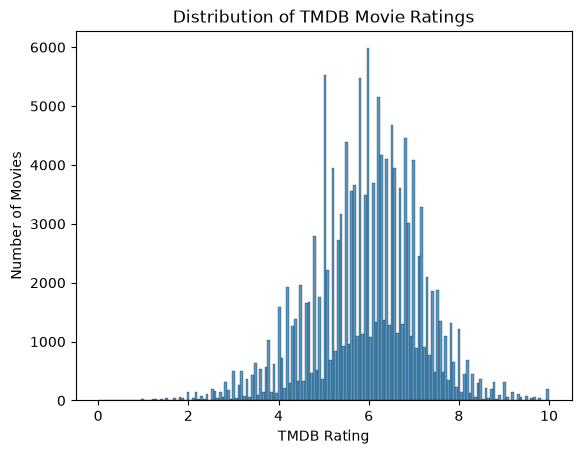

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x='vote_average')

plt.title('Distribution of TMDB Movie Ratings')
plt.xlabel('TMDB Rating')
plt.ylabel('Number of Movies')
plt.show()

This histogram shows the distribution of TMDB movie ratings across the dataset. Most movies appear to have a rating between 5-7 with a high concentration around 6. 

I will merge the TMDB dataset with IMDb and Rotten Tomatoes rating data using movie identifiers, then add streaming service information. For my analysis, I plan to use boxplots to compare rating distributions across websites and across streaming services. I will then investigate a regression model that includes website, streaming service, and their interaction to test whether rating differences vary across services.